In [ ]:
import os
from google.colab import drive

In [2]:
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
os.listdir('/content/drive/MyDrive/Dataset')

['WIN_20260207_10_59_32_Pro.jpg',
 'acne-open-comedo-59.jpeg',
 'train',
 'Dataset.zip',
 'testing',
 'facial_model.keras']

In [ ]:
train_dataset = "/content/drive/MyDrive/Dataset/train"
test_dataset = "/content/drive/MyDrive/Dataset/testing"

In [ ]:
os.listdir(train_dataset)

['Wrinkle', 'Rosacea', 'Normal', 'Acne', 'Hyperpigmentation', 'Eczemaa']

In [ ]:
os.listdir(test_dataset)

['Acne', 'Eczemaa', 'Hyperpigmentation', 'Normal', 'Rosacea', 'Wrinkle']

In [7]:
train_count = {}
for image in os.listdir(train_dataset):
    image_path = os.path.join(train_dataset,image)
    train_count[image] = len(os.listdir(image_path))
print(train_count)

{'Wrinkle': 1000, 'Rosacea': 1086, 'Normal': 1142, 'Acne': 1092, 'Hyperpigmentation': 1096, 'Eczemaa': 1154}


In [8]:
test_count = {}
for image in os.listdir(test_dataset):
    image_path = os.path.join(test_dataset,image)
    test_count[image] = len(os.listdir(image_path))
print(test_count)

{'Acne': 222, 'Eczemaa': 246, 'Hyperpigmentation': 117, 'Normal': 346, 'Rosacea': 145, 'Wrinkle': 100}


In [9]:
classes = test_count.keys()
print(classes)

dict_keys(['Acne', 'Eczemaa', 'Hyperpigmentation', 'Normal', 'Rosacea', 'Wrinkle'])


In [10]:
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

In [23]:
train_data = image_dataset_from_directory(
    train_dataset,
    validation_split = 0.2,
    subset = "training",
    color_mode = "rgb",
    image_size = (224,224),
    shuffle = True,
    seed = 42,
    batch_size = 32
    )

val_data = image_dataset_from_directory(
    train_dataset,
    validation_split = 0.2,
    subset = "validation",
    color_mode = "rgb",
    image_size =(224,224),
    shuffle = False,
    seed = 42,
    batch_size = 32
)

Found 6570 files belonging to 6 classes.
Using 5256 files for training.
Found 6570 files belonging to 6 classes.
Using 1314 files for validation.


In [24]:
test_data = image_dataset_from_directory(
    test_dataset,
    color_mode = "rgb",
    image_size = (224,224),
    shuffle = False,
    
    seed = 42,
    batch_size = 32
    )

Found 1176 files belonging to 6 classes.


In [25]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential


In [26]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)


base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

In [27]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2
)

In [28]:
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(6, activation="softmax")
])

In [29]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.fit(
    train_data,
    validation_data=val_data,
    epochs=30
)

Epoch 1/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 135s 366ms/step - accuracy: 0.7955 - loss: 0.6021
Epoch 2/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 22s 134ms/step - accuracy: 0.8904 - loss: 0.3354
Epoch 3/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 22s 131ms/step - accuracy: 0.9178 - loss: 0.2464
Epoch 4/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.9315 - loss: 0.2104
Epoch 5/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 21s 128ms/step - accuracy: 0.9382 - loss: 0.1861
Epoch 6/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 22s 132ms/step - accuracy: 0.9496 - loss: 0.1532
Epoch 7/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 21s 128ms/step - accuracy: 0.9637 - loss: 0.1094
Epoch 8/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 41s 129ms/step - accuracy: 0.9463 - loss: 0.1646
Epoch 9/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 22s 133ms/step - accuracy: 0.9583 - loss: 0.1295
Epoch 10/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 22s 131ms/step - accuracy: 0.9678 - loss: 0.0980
Epoch 11/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 21s 128ms/step - accuracy: 0.9646 - loss: 0.1097
Epoch 12/30
165/16

In [31]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,558,895 (47.91 MB)

 Trainable params: 4,172,290 (15.92 MB)

 Non-trainable params: 42,023 (164.16 KB)

 Optimizer params: 8,344,582 (31.83 MB)

In [33]:
model.evaluate(test_data)

37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.7245 - loss: 2.6562


[2.656181812286377, 0.7244898080825806]

In [ ]:
model.save("/content/drive/MyDrive/Dataset/facial_model.keras")

In [ ]:
from PIL import Image

In [ ]:
image = "/content/drive/MyDrive/Dataset/acne-open-comedo-59.jpeg"

In [ ]:
import numpy as np

In [ ]:
img = Image.open(image)
img = img.convert("RGB")
img = img.resize((224,224))
img = np.array(img)
print(img)

[[[ 52  32  31]
  [ 54  34  33]
  [ 56  36  33]
  ...
  [107  69  69]
  [ 99  62  63]
  [102  66  66]]

 [[ 50  30  29]
  [ 52  32  31]
  [ 57  37  35]
  ...
  [107  69  68]
  [100  64  62]
  [ 97  61  61]]

 [[ 52  32  31]
  [ 58  38  37]
  [ 72  51  49]
  ...
  [104  67  63]
  [102  66  63]
  [ 99  64  62]]

 ...

 [[101  64  65]
  [104  64  65]
  [106  66  66]
  ...
  [146  94  91]
  [149  97  93]
  [148  94  89]]

 [[ 99  60  60]
  [ 96  57  58]
  [ 99  58  59]
  ...
  [153 100  97]
  [152  99  95]
  [146  92  88]]

 [[ 94  55  56]
  [ 93  55  56]
  [100  60  61]
  ...
  [150  98  93]
  [147  95  91]
  [148  96  92]]]


In [ ]:
print(type(img))
print(img.shape)
print(model.input_shape)

<class 'numpy.ndarray'>
(224, 224, 3)
(None, 224, 224, 3)


In [ ]:
import numpy as np

img = np.expand_dims(img, axis=0)

print(img.shape)

(1, 224, 224, 3)


In [ ]:
prediction = model.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


In [ ]:
print(prediction)

[[9.6258903e-01 3.7405442e-02 5.5114251e-06 2.9288658e-10 1.8547167e-08
  1.2897702e-08]]


In [ ]:
for class_name, probability in zip(classes, prediction[0]):
    print(f"{class_name}: {probability*100:.2f}%")

Acne: 96.26%
Eczemaa: 3.74%
Hyperpigmentation: 0.00%
Normal: 0.00%
Rosacea: 0.00%
Wrinkle: 0.00%


In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Class": classes,
    "Confidence (%)": prediction[0] * 100
})

print(df)

               Class  Confidence (%)
0               Acne    9.625890e+01
1            Eczemaa    3.740544e+00
2  Hyperpigmentation    5.511425e-04
3             Normal    2.928866e-08
4            Rosacea    1.854717e-06
5            Wrinkle    1.289770e-06


In [ ]:
image = "/content/drive/MyDrive/Dataset/WIN_20260207_10_59_32_Pro.jpg"
img = Image.open(image)
img = img.convert("RGB")
img = img.resize((224,224))


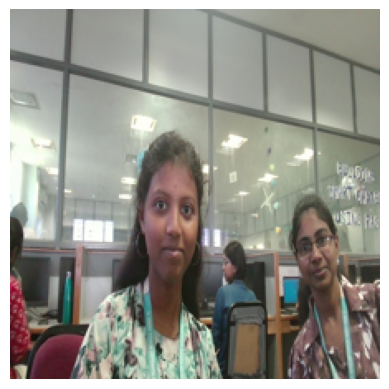

In [ ]:
from matplotlib import pyplot as plt

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
img.show()

In [ ]:
img = np.array(img)
img = np.expand_dims(img, axis=0)
prediction = model.predict(img)
for class_name, probability in zip(classes, prediction[0]):
    print(f"{class_name}: {probability*100:.2f}%")

In [ ]:
img.show()

AttributeError: 'numpy.ndarray' object has no attribute 'show'

In [34]:
import cv2

print(cv2.__file__)
print(cv2.__version__)
print(hasattr(cv2, "CascadeClassifier"))

/usr/local/lib/python3.12/dist-packages/cv2/__init__.py
4.13.0
True
